# Tensor Decompositions for Multiway Data — Master Reproducibility Notebook
Este notebook importa los módulos de `src/` y reproduce todos los resultados numéricos y figuras del reporte.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import tensorly as tl

from src.tensor_utils import unfold_kb, fold_kb, khatri_rao, mode_dot, cp_to_tensor_kb, jennrich_cp, corcondia
from src.plot_style import apply_paper_style
from src import experiments_A as expA
from src.experiments_B import run_experiment_e1, run_experiment_e4a, run_experiment_e4b

apply_paper_style()
print(f"Workspace root: {root}")

Workspace root: c:\tensor-decompositions


# Persona A — Verificación y experimentos teóricos

Esta sección ejecuta las comprobaciones algebraicas, los casos degenerados y las aplicaciones de la Persona A.


=== Verification of identities (protocol step 1) ===
  lemma_2_3                              True
  lemma_4_1                              True
  prop_pca_signs                         True
  prop_tucker_indet                      True
  thm_hosvd_chain                        True
  prop_3_1_and_rem_central               True
  three_cubes                            True
  prop_222_decomposition                 True
  thm_not_closed_construction            True
  prop_restore_orthonormal_gram          True
  self_test_w_state_norm                 True
  self_test_multilinear_rank_w           True

=== Smoke test (proposal Sec. 7.3) ===
  mlrank_D                               (2, 2, 2)
  unfoldings_equal                       True
  tucker222_fit_error                    0.0
  disc_D                                 1.0
  cpD_err_10                             0.06117002919989774
  cpD_wmax_10                            2.208988701155094
  cpD_err_100                            0.0317

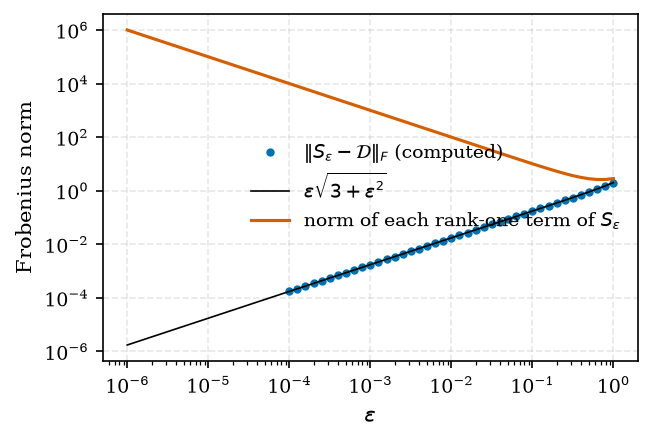

In [2]:
# Verifica identidades de rangos, transformaciones, HOSVD, S_eps y construcciones de límite.
res_verify_A = expA.verify_identities()
assert all(res_verify_A.values()), "Existe al menos una identidad fallida en Persona A."

# Smoke test y familia S_eps.
res_smoke_A = expA.smoke_test()
res_seps_A = expA.s_epsilon_check()

## Verificación Numérica de Identidades Algebraicas (Protocolo Paso 1)
Comprueba Fórmula (1), Teorema de Jennrich y pérdida de rango 1 tras rotación $\mathbf{Q}^{-T}$.

In [7]:
rng = np.random.default_rng(42)
A = rng.standard_normal((10, 3))
B = rng.standard_normal((8, 3))
C = rng.standard_normal((6, 3))
T = cp_to_tensor_kb(A, B, C)

# 1. Fórmula (1): T_(1) = A (C \odot B)^T
assert np.allclose(unfold_kb(T, 0), A @ khatri_rao(C, B).T)

# 2. Algoritmo de Jennrich
A_rec, B_rec, C_rec = jennrich_cp(T, r=3, seed=42)
assert np.linalg.norm(T - cp_to_tensor_kb(A_rec, B_rec, C_rec)) < 1e-12
print('[OK] Identidades de Persona B verificadas a precisión de máquina.')

[OK] Identidades de Persona B verificadas a precisión de máquina.


## Experimentos E2, E3 y comprobación de Strassen

Ejecuta HOSVD/HOOI, degeneración CP-ALS, Monte Carlo y la descomposición rank-7 de Strassen.

[OK] Figura exportada en: figures_export\E2_hosvd_vs_hooi.pdf

=== Experiment E2 ===
  n_tensors                              360
  median_lower_ratio                     1.0224879095704105
  max_lower_ratio                        1.105992231780372
  max_upper_ratio                        1.5666613161031606
  bound_violations                       0
  hooi_worse_than_hosvd                  0
  max_lower_gaussian                     1.0697204982489603
  median_lower_gaussian                  1.0347366975653696
  max_upper_gaussian                     1.258693745405646
  max_lower_lowrank_noise                1.0090797301430425
  median_lower_lowrank_noise             1.0011319516271884
  max_upper_lowrank_noise                1.1686819418688648
  max_lower_graded                       1.105992231780372
  median_lower_graded                    1.0224879095704105
  max_upper_graded                       1.5666613161031606
  adversarial_max_ratio_222              1.4175480943314656
  adver

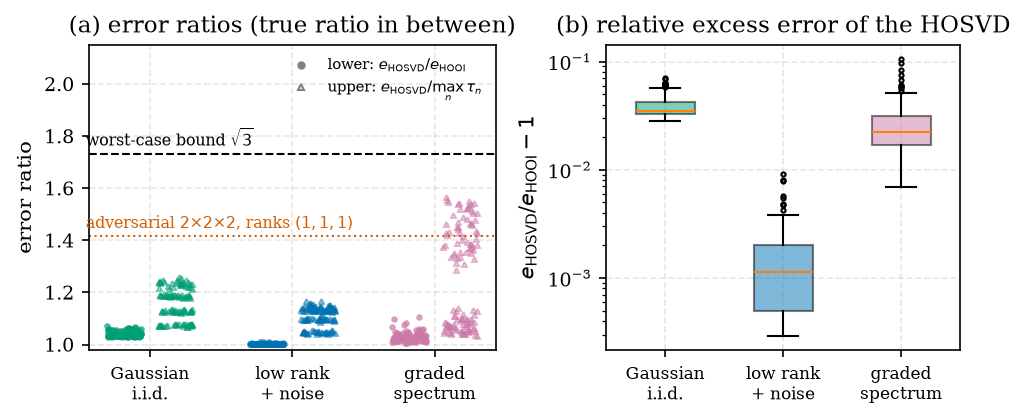

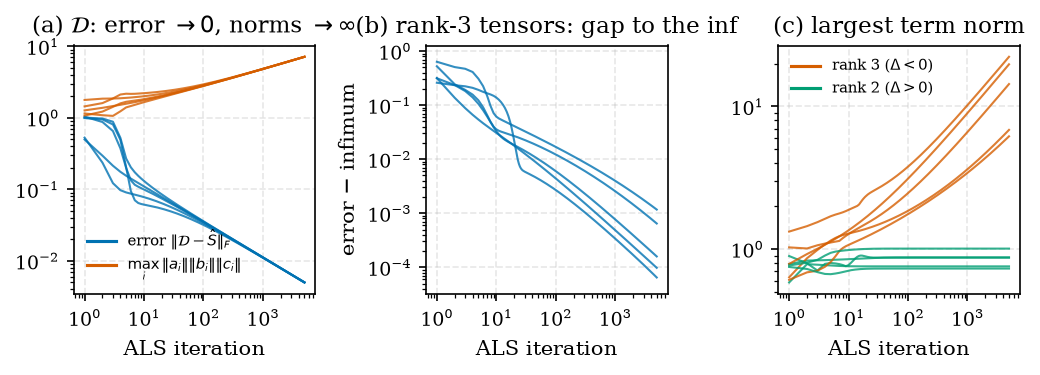

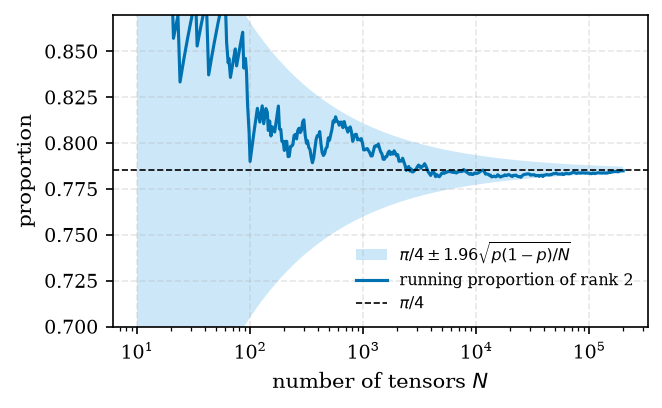

In [3]:
res_e2_A = expA.experiment_E2(n_trials=30, adversarial=True)
res_e3_A = expA.experiment_E3(n_iter=5000, n_runs=5, n_mc=200_000)
res_strassen_A = expA.strassen_check()

expA.write_results_tex(res_smoke_A, res_seps_A, res_e2_A, res_e3_A, res_strassen_A)
print("Resultados LaTeX generados correctamente.")

## Experimentos Persona B: E1 (Rotación vs. Unicidad), E4(a) (Fluorescencia) y E4(b) (WDI Social)

In [4]:
res_e1 = run_experiment_e1()
res_e4a = run_experiment_e4a()
res_e4b = run_experiment_e4b()

[OK] Figura exportada en: figures_export\fig_E1_congruence.pdf
[OK] Figura exportada en: figures_export\fig_E1_reshaped_loadings.pdf

=== RESUMEN EXPERIMENTO E1 (10% RUIDO) ===
CP-ALS     -> phi_B = 0.9997 ± 0.0002 | phi_C = 1.0000 ± 0.0000
Tucker     -> phi_B = 0.8043 ± 0.0842 | phi_C = 0.4902 ± 0.0431
PCA Aplan. -> phi_B = 0.8528 ± 0.0823 | phi_C = 0.9904 ± 0.0156
Energía fuera de rango-1 en PCA aplanado (10% ruido): 22.11%
[OK] Figura exportada en: figures_export\fig_E4a_fluorescence.pdf

=== RESUMEN EXPERIMENTO E4(a) FLUORESCENCIA ===
  cp_rel_error: 0.025049
  nn_cp_rel_error: 0.025145
  restart_congruence_em_mean: 1.000000
  restart_congruence_ex_mean: 1.000000
  unconstrained_vs_nn_phi_em: 0.999991
  unconstrained_vs_nn_phi_ex: 1.000000
  corcondia_r3: 97.495148
[OK] Figura exportada en: figures_export\fig_E4b_social_analysis.pdf

=== RESUMEN EXPERIMENTO E4(b) CIENCIAS SOCIALES (WDI) ===
CORCONDIA (Mode-0 Center) por r=1..5: [39.36, 56.87, 66.09, 73.4, 80.51]
CORCONDIA (Double C